<a href="https://colab.research.google.com/github/mmatinm/SmartCane-AI-Visual-Navigation-System/blob/main/training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Functions

In [2]:
import os
import yaml
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def report_yolo_dataset(dataset_dir, show_examples=True, num_examples=8):
    def count_images(split):
        img_dir = os.path.join(dataset_dir, split, "images")
        if os.path.exists(img_dir):
            return len([f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        else:
            return 0

    def analyze_split_labels(split, num_classes):
        label_dir = os.path.join(dataset_dir, split, "labels")
        class_image_counts = [0] * num_classes
        overlap_count = 0
        empty_or_missing_count = 0

        image_dir = os.path.join(dataset_dir, split, "images")
        if not os.path.exists(image_dir):
            return class_image_counts, overlap_count, empty_or_missing_count

        image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

        for img_file in image_files:
            img_stem = os.path.splitext(img_file)[0]
            label_path = os.path.join(label_dir, img_stem + ".txt")
            classes_in_image = set()

            if os.path.exists(label_path):
                with open(label_path, 'r') as f:
                    lines = f.readlines()
                    for line in lines:
                        parts = line.strip().split()
                        if len(parts) >= 1:
                            cls_id = int(float(parts[0]))
                            if 0 <= cls_id < num_classes:
                                classes_in_image.add(cls_id)
            else:
                empty_or_missing_count += 1
                continue  # no label file

            if len(classes_in_image) == 0:
                empty_or_missing_count += 1
            else:
                if len(classes_in_image) > 1:
                    overlap_count += 1
                for cls_id in classes_in_image:
                    class_image_counts[cls_id] += 1

        return class_image_counts, overlap_count, empty_or_missing_count

    # Print image counts
    train_count = count_images("train")
    valid_count = count_images("valid")
    test_count = count_images("test")

    print(f"📊 Image counts:")
    print(f"  Train: {train_count}")
    print(f"  Validation: {valid_count}")
    print(f"  Test: {test_count}")

    # Load class names
    data_yaml_path = os.path.join(dataset_dir, "data.yaml")
    with open(data_yaml_path, 'r') as f:
        data_yaml = yaml.safe_load(f)

    class_names = data_yaml.get("names", [])
    num_classes = len(class_names)

    print("\n🏷️ Classes in dataset:")
    for i, cls in enumerate(class_names):
        print(f"  {i}: {cls}")

    # Count per-class image occurrences and extra stats
    print("\n📂 Per-class image counts (number of images where each class appears):")
    for split in ["train", "valid", "test"]:
        class_image_counts, overlap_count, empty_count = analyze_split_labels(split, num_classes)
        print(f"  {split.capitalize()}:")
        for i, count in enumerate(class_image_counts):
            print(f"    {class_names[i]} ({i}): {count}")
        print(f"    ➕ Overlap images (contain ≥2 classes): {overlap_count}")
        print(f"    🚫 Images without any class (empty or missing labels): {empty_count}")

    if not show_examples:
        return

    # Pick examples from train split
    image_dir = os.path.join(dataset_dir, "train", "images")
    label_dir = os.path.join(dataset_dir, "train", "labels")

    image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if len(image_files) == 0:
        print("\n⚠️ No images found in train/images to display.")
        return

    sample_files = random.sample(image_files, min(num_examples, len(image_files)))

    print(f"\n🖼️ Showing {len(sample_files)} random annotated images...")

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for ax, fname in zip(axes, sample_files):
        img_path = os.path.join(image_dir, fname)
        label_path = os.path.join(label_dir, os.path.splitext(fname)[0] + ".txt")

        image = Image.open(img_path)
        w, h = image.size
        ax.imshow(image)
        ax.axis('off')

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue
                    cls_id, xc, yc, bw, bh = map(float, parts)
                    x = (xc - bw / 2) * w
                    y = (yc - bh / 2) * h
                    box_w = bw * w
                    box_h = bh * h
                    rect = patches.Rectangle((x, y), box_w, box_h,
                                             linewidth=2, edgecolor='red', facecolor='none')
                    ax.add_patch(rect)
                    if class_names:
                        ax.text(x, y, class_names[int(cls_id)], color='yellow', fontsize=10,
                                bbox=dict(facecolor='black', alpha=0.5))

    plt.tight_layout()
    plt.show()


# Merging

In [ ]:

!cp -r "/content/drive/MyDrive/SmartCane/final_bus" /content/
!cp -r "/content/drive/MyDrive/SmartCane/final_crosswalk" /content/
!cp -r "/content/drive/MyDrive/SmartCane/final_escalator" /content/
!cp -r "/content/drive/MyDrive/SmartCane/final_rglight" /content/
!cp -r "/content/drive/MyDrive/SmartCane/final_safety" /content/


In [ ]:
import os
import shutil
import yaml
from tqdm import tqdm

# List of dataset paths
datasets = [
    "/content/final_bus",
    "/content/final_crosswalk",
    "/content/final_escalator",
    "/content/final_rglight",
    "/content/final_safety"
]

# Output folder
output_dir = "/content/merged1"
splits = ["train", "valid", "test"]

# Make merged folders
for split in splits:
    os.makedirs(os.path.join(output_dir, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(output_dir, split, "labels"), exist_ok=True)

global_class_names = []
class_offset = 0

# Merge process
for dataset in datasets:
    dataset_name = os.path.basename(dataset)

    # Read class names from data.yaml
    data_yaml_path = os.path.join(dataset, "data.yaml")
    with open(data_yaml_path, "r") as f:
        data_yaml = yaml.safe_load(f)

    local_names = data_yaml.get("names", [])
    if isinstance(local_names, dict):
        # convert dict to list
        local_names = [local_names[k] for k in sorted(local_names.keys())]

    # Append local names to global list
    global_class_names.extend(local_names)

    for split in splits:
        img_dir = os.path.join(dataset, split, "images")
        lbl_dir = os.path.join(dataset, split, "labels")
        out_img_dir = os.path.join(output_dir, split, "images")
        out_lbl_dir = os.path.join(output_dir, split, "labels")

        if not os.path.exists(img_dir):
            continue

        image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        pbar = tqdm(image_files, desc=f"Merging {split} from {dataset_name}", ncols=100)

        for img_file in pbar:
            base_name = os.path.splitext(img_file)[0]
            src_img_path = os.path.join(img_dir, img_file)
            src_lbl_path = os.path.join(lbl_dir, base_name + ".txt")

            # Rename with dataset prefix to avoid name clashes
            new_base = f"{dataset_name}_{base_name}"
            dst_img_path = os.path.join(out_img_dir, new_base + ".jpg")
            dst_lbl_path = os.path.join(out_lbl_dir, new_base + ".txt")

            shutil.copy2(src_img_path, dst_img_path)

            if os.path.exists(src_lbl_path):
                with open(src_lbl_path, "r") as f:
                    lines = f.readlines()

                new_lines = []
                for line in lines:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    old_cls = int(parts[0])
                    new_cls = old_cls + class_offset
                    new_line = f"{new_cls} " + " ".join(parts[1:]) + "\n"
                    new_lines.append(new_line)

                with open(dst_lbl_path, "w") as f:
                    f.writelines(new_lines)

    class_offset += len(local_names)

# Write final merged data.yaml
final_yaml = {
    "train": os.path.join(output_dir, "train/images"),
    "val": os.path.join(output_dir, "valid/images"),
    "test": os.path.join(output_dir, "test/images"),
    "nc": len(global_class_names),
    "names": global_class_names
}

with open(os.path.join(output_dir, "data.yaml"), "w") as f:
    yaml.dump(final_yaml, f)

print("✅ Merge complete with class remapping.")


Merging test from final_safety: 100%|█████████████████████████████| 82/82 [00:00<00:00, 1439.70it/s]

✅ Merge complete with class remapping.


In [ ]:
report_yolo_dataset('/content/drive/MyDrive/SmartCane/final_dataset')

In [ ]:
import shutil

# Source and destination paths
src = "/content/merged1"
dst = "/content/drive/MyDrive/SmartCane/final_dataset"

# Copy folder recursively
shutil.copytree(src, dst)
print(f"✅ Dataset copied to {dst}")

✅ Dataset copied to /content/drive/MyDrive/SmartCane/final_dataset


# Preprocessing

In [7]:

!cp -r "/content/drive/MyDrive/SmartCane/final_dataset" /content/

In [ ]:
import os

# Define the folder and output zip file path
folder_path = "/content/drive/MyDrive/SmartCane/final_dataset"
zip_path = "/content/drive/MyDrive/SmartCane/final_dataset.zip"

# Run the zip command
!zip -r "{zip_path}" "{folder_path}"

In [ ]:
import os
import cv2
import yaml
import shutil
import random
from glob import glob
from tqdm import tqdm
import albumentations as A

# Define augmentation pipeline
def get_augmentations():
    return A.Compose([
        A.Resize(640, 640),
        A.RandomBrightnessContrast(p=0.3),
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=15, p=0.4),
        A.Blur(p=0.2),
        A.CLAHE(p=0.1),
    ], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'], min_visibility=0.3))

# Load YOLO-format label
def load_yolo_label(label_path):
    boxes = []
    with open(label_path, 'r') as f:
        for line in f.readlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                cls, x, y, w, h = map(float, parts[:5])
                boxes.append([x, y, w, h, int(cls)])
    return boxes

# Save YOLO-format label
def save_yolo_label(label_path, boxes):
    with open(label_path, 'w') as f:
        for box in boxes:
            x, y, w, h, cls = box
            f.write(f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

# Augment and save
def augment_and_save(img_path, label_path, out_img_dir, out_label_dir, num_aug=3):
    image = cv2.imread(img_path)
    h, w = image.shape[:2]
    boxes = load_yolo_label(label_path)

    for i in range(num_aug):
        bboxes = [[x, y, bw, bh] for x, y, bw, bh, _ in boxes]
        class_labels = [cls for *_, cls in boxes]

        aug = get_augmentations()
        try:
            augmented = aug(image=image, bboxes=bboxes, class_labels=class_labels)
        except:
            continue

        new_img = augmented['image']
        new_boxes = augmented['bboxes']
        new_labels = augmented['class_labels']

        if not new_boxes:
            continue

        out_img_name = os.path.splitext(os.path.basename(img_path))[0] + f"_{i}.jpg"
        out_label_name = os.path.splitext(os.path.basename(label_path))[0] + f"_{i}.txt"

        cv2.imwrite(os.path.join(out_img_dir, out_img_name), new_img)
        save_yolo_label(os.path.join(out_label_dir, out_label_name),
                        [[*box, cls] for box, cls in zip(new_boxes, new_labels)])

# Preprocess dataset
def preprocess_yolo_dataset(input_dir, output_dir):
    splits = ['train', 'valid', 'test']
    for split in splits:
        print(f"Processing split: {split}")
        image_dir = os.path.join(input_dir, split, 'images')
        label_dir = os.path.join(input_dir, split, 'labels')

        out_img_dir = os.path.join(output_dir, split, 'images')
        out_label_dir = os.path.join(output_dir, split, 'labels')
        os.makedirs(out_img_dir, exist_ok=True)
        os.makedirs(out_label_dir, exist_ok=True)

        for img_path in tqdm(glob(os.path.join(image_dir, '*.jpg'))):
            base_name = os.path.splitext(os.path.basename(img_path))[0]
            label_path = os.path.join(label_dir, base_name + '.txt')

            if not os.path.exists(label_path):
                continue

            if split == 'train':
                # Apply 3 augmentations to each training image
                augment_and_save(img_path, label_path, out_img_dir, out_label_dir, num_aug=3)
            else:
                # For valid/test: just resize the image once without augmentation
                augment_and_save(img_path, label_path, out_img_dir, out_label_dir, num_aug=1)

# Generate data.yaml
def create_data_yaml(output_dir, class_names):
    data = {
        'train': os.path.join(output_dir, 'train', 'images'),
        'val': os.path.join(output_dir, 'valid', 'images'),
        'test': os.path.join(output_dir, 'test', 'images'),
        'nc': len(class_names),
        'names': class_names
    }

    with open(os.path.join(output_dir, 'data.yaml'), 'w') as f:
        yaml.dump(data, f)

def extract_class_names_from_yaml(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    return data['names']

# Example usage

input_dataset = '/content/final_dataset'
output_dataset = '/content/augmented_dataset400'

# Dynamically extract class names
yaml_path = '/content/final_dataset/data.yaml'
class_names = extract_class_names_from_yaml(yaml_path)


preprocess_yolo_dataset(input_dataset, output_dataset)
create_data_yaml(output_dataset, class_names)


Processing split: train


100%|██████████| 7676/7676 [05:19<00:00, 24.02it/s]


Processing split: valid


100%|██████████| 1236/1236 [00:22<00:00, 54.75it/s]


Processing split: test


100%|██████████| 1482/1482 [00:26<00:00, 55.72it/s]


In [ ]:
import shutil

# Source and destination paths
src = "/content/augmented_dataset400"
dst = "/content/drive/MyDrive/SmartCane/augmented_dataset"

# Copy folder recursively
shutil.copytree(src, dst)
print(f"✅ Dataset copied to {dst}")

✅ Dataset copied to /content/drive/MyDrive/SmartCane/augmented_dataset


In [ ]:
import os
print(os.path.exists('/content/drive/MyDrive/SmartCane/augmented_dataset/data.yaml'))


True


In [ ]:
report_yolo_dataset('/content/final_dataset')

In [ ]:
import shutil

#shutil.rmtree('/content/augmented_dataset200')


# Train

In [ ]:
import yaml
import os

yaml_path = "/content/augmented_dataset400/data.yaml"

# Load existing data.yaml
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Update paths to be relative
data['train'] = './train/images'
data['val'] = './valid/images'
data['test'] = './test/images'

# Save the updated YAML
with open(yaml_path, 'w') as f:
    yaml.dump(data, f, default_flow_style=False)

print("✅ data.yaml updated with relative paths.")


✅ data.yaml updated with relative paths.


In [ ]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 72.2 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12


In [ ]:
from ultralytics import YOLO

# Load model (you can change to yolov8m.pt or yolov8l.pt)
# Load pretrained model
model = YOLO("yolov8n.pt")



In [ ]:
# Freeze all first
for param in model.model.parameters():
    param.requires_grad = False

# Unfreeze detection head + neck (from model.15 onward)
for i in [15, 16, 18, 19, 21, 22]:
    for param in model.model.model[i].parameters():
        param.requires_grad = True

In [ ]:
# Print layer trainability
frozen = []
trainable = []

for name, param in model.model.named_parameters():
    if not param.requires_grad:
        frozen.append(name)
    else:
        trainable.append(name)

print(f"🔒 Frozen layers: {len(frozen)}")
for name in frozen:
    print("  🔒", name)

print(f"\n🟢 Trainable layers: {len(trainable)}")
for name in trainable:
    print("  🟢", name)

🔒 Frozen layers: 93
  🔒 model.0.conv.weight
  🔒 model.0.bn.weight
  🔒 model.0.bn.bias
  🔒 model.1.conv.weight
  🔒 model.1.bn.weight
  🔒 model.1.bn.bias
  🔒 model.2.cv1.conv.weight
  🔒 model.2.cv1.bn.weight
  🔒 model.2.cv1.bn.bias
  🔒 model.2.cv2.conv.weight
  🔒 model.2.cv2.bn.weight
  🔒 model.2.cv2.bn.bias
  🔒 model.2.m.0.cv1.conv.weight
  🔒 model.2.m.0.cv1.bn.weight
  🔒 model.2.m.0.cv1.bn.bias
  🔒 model.2.m.0.cv2.conv.weight
  🔒 model.2.m.0.cv2.bn.weight
  🔒 model.2.m.0.cv2.bn.bias
  🔒 model.3.conv.weight
  🔒 model.3.bn.weight
  🔒 model.3.bn.bias
  🔒 model.4.cv1.conv.weight
  🔒 model.4.cv1.bn.weight
  🔒 model.4.cv1.bn.bias
  🔒 model.4.cv2.conv.weight
  🔒 model.4.cv2.bn.weight
  🔒 model.4.cv2.bn.bias
  🔒 model.4.m.0.cv1.conv.weight
  🔒 model.4.m.0.cv1.bn.weight
  🔒 model.4.m.0.cv1.bn.bias
  🔒 model.4.m.0.cv2.conv.weight
  🔒 model.4.m.0.cv2.bn.weight
  🔒 model.4.m.0.cv2.bn.bias
  🔒 model.4.m.1.cv1.conv.weight
  🔒 model.4.m.1.cv1.bn.weight
  🔒 model.4.m.1.cv1.bn.bias
  🔒 model.4.m.1.cv2.

In [ ]:
!du -sh /content/augmented_dataset400


3.3G	/content/augmented_dataset400


In [ ]:
model.train(
    data='/content/augmented_dataset400/data.yaml',  # absolute path to YAML
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,  # first GPU
    name='yolov8_custom',
    project='/content/yolo_train_output',
    workers=4,
    cash = True
)

Ultralytics 8.3.176 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/augmented_dataset400/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8_custom6, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=

train: Scanning /content/augmented_dataset400/train/labels.cache... 22515 images, 0 backgrounds, 0 corrupt: 100%|██████████| 22515/22515 [00:00<?, ?it/s]


WARNING ⚠️ train: 38.6GB disk space required, with 50% safety margin but only 36.0/112.6GB free, not caching images to disk
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1053.0±764.7 MB/s, size: 197.6 KB)


val: Scanning /content/augmented_dataset400/valid/labels.cache... 1211 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1211/1211 [00:00<?, ?it/s]
val: Caching images (1.4GB Disk): 100%|██████████| 1211/1211 [00:00<00:00, 33518.56it/s]


Plotting labels to /content/yolo_train_output/yolov8_custom6/labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000833, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to /content/yolo_train_output/yolov8_custom6
Starting training for 10 epochs...
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


       1/10      7.99G      1.315      2.499      1.605         71        640:  17%|█▋        | 60/352 [01:33<07:35,  1.56s/it]


KeyboardInterrupt: 

# save

In [ ]:
# Define source and destination
src_path = "/content/yolo_train_output/yolov8_custom5/weights/best.pt"
dst_path = "/content/drive/MyDrive/SmartCane/yolov8n_0.83.pt"

# Copy the file
!cp "{src_path}" "{dst_path}"


In [3]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 77.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
 

In [4]:
from ultralytics import YOLO

# Load the trained model from Google Drive
model = YOLO("/content/drive/MyDrive/SmartCane/yolov8n_0.88.pt")



Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# Test

In [5]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from IPython.display import Image, display

def evaluate_yolov8_detector(model_path, data_yaml, split='test'):
    model = YOLO(model_path)

    # Run validation and ensure plots are saved
    results = model.val(
        data=data_yaml,
        split=split,
        save_json=True,
        save_txt=True,
        iou=0.5,
        plots=True  # 👈 this makes it save confusion_matrix.png, PR_curve.png, etc.
    )

    # Extract metrics
    mp, mr, map50, map = results.box.mean_results()
    print("\n📊 Detection Evaluation Metrics")
    print(f"Precision:     {mp:.3f}")
    print(f"Recall:        {mr:.3f}")
    print(f"mAP@0.5:       {map50:.3f}")
    print(f"mAP@0.5:0.95:  {map:.3f}")

    # ✅ Show saved PR and Confusion Matrix plots (if they exist)
    save_dir = Path(results.save_dir)
    for plot_name in ["confusion_matrix.png", "PR_curve.png"]:
        plot_path = save_dir / plot_name
        if plot_path.exists():
            display(Image(str(plot_path)))
        else:
            print(f"⚠️ Warning: {plot_name} not found in {save_dir}")

    # ✅ Optional: Visualize predictions on 5 images from test folder (you must set this manually)
    test_imgs_dir = Path("/content/drive/MyDrive/SmartCane/final_dataset/test/images")  # set manually
    if test_imgs_dir.exists():
        test_imgs = list(test_imgs_dir.glob("*.jpg"))[50:55]
        for img_path in test_imgs:
            im = cv2.imread(str(img_path))
            pred_results = model.predict(source=im, conf=0.25, save=False)
            annotated = pred_results[0].plot()
            plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
            plt.title(f"Prediction: {img_path.name}")
            plt.axis('off')
            plt.show()
    else:
        print(f"⚠️ Warning: Test images not found at {test_imgs_dir}")


Ultralytics 8.3.176 🚀 Python-3.11.13 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
Model summary (fused): 72 layers, 3,007,208 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.9±0.4 ms, read: 21.1±20.9 MB/s, size: 64.7 KB)


val: Scanning /content/drive/MyDrive/SmartCane/final_dataset/test/labels.cache... 1482 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1482/1482 [00:00<?, ?it/s]

WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 25, len(boxes) = 1672. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 93/93 [07:19<00:00,  4.73s/it]


                   all       1482       1672      0.872      0.827      0.877      0.546
               shelter        200        200       0.94      0.875      0.938      0.657
             crosswalk        200        207      0.972      0.942      0.961      0.835
             Escalator        200        339      0.806      0.846      0.861      0.556
             downstair        200        201      0.884      0.871      0.917      0.489
               upstair        200        207      0.837      0.763      0.831      0.463
                 green        200        205      0.857      0.898      0.914      0.419
                   red        200        206       0.86      0.801      0.865      0.386
           safety-line         82        107      0.822      0.617      0.729      0.566
Speed: 8.0ms preprocess, 259.9ms inference, 0.0ms loss, 0.6ms postprocess per image
Saving runs/detect/val3/predictions.json...
Results saved to runs/detect/val3

📊 Detection Evaluation Metrics
Preci

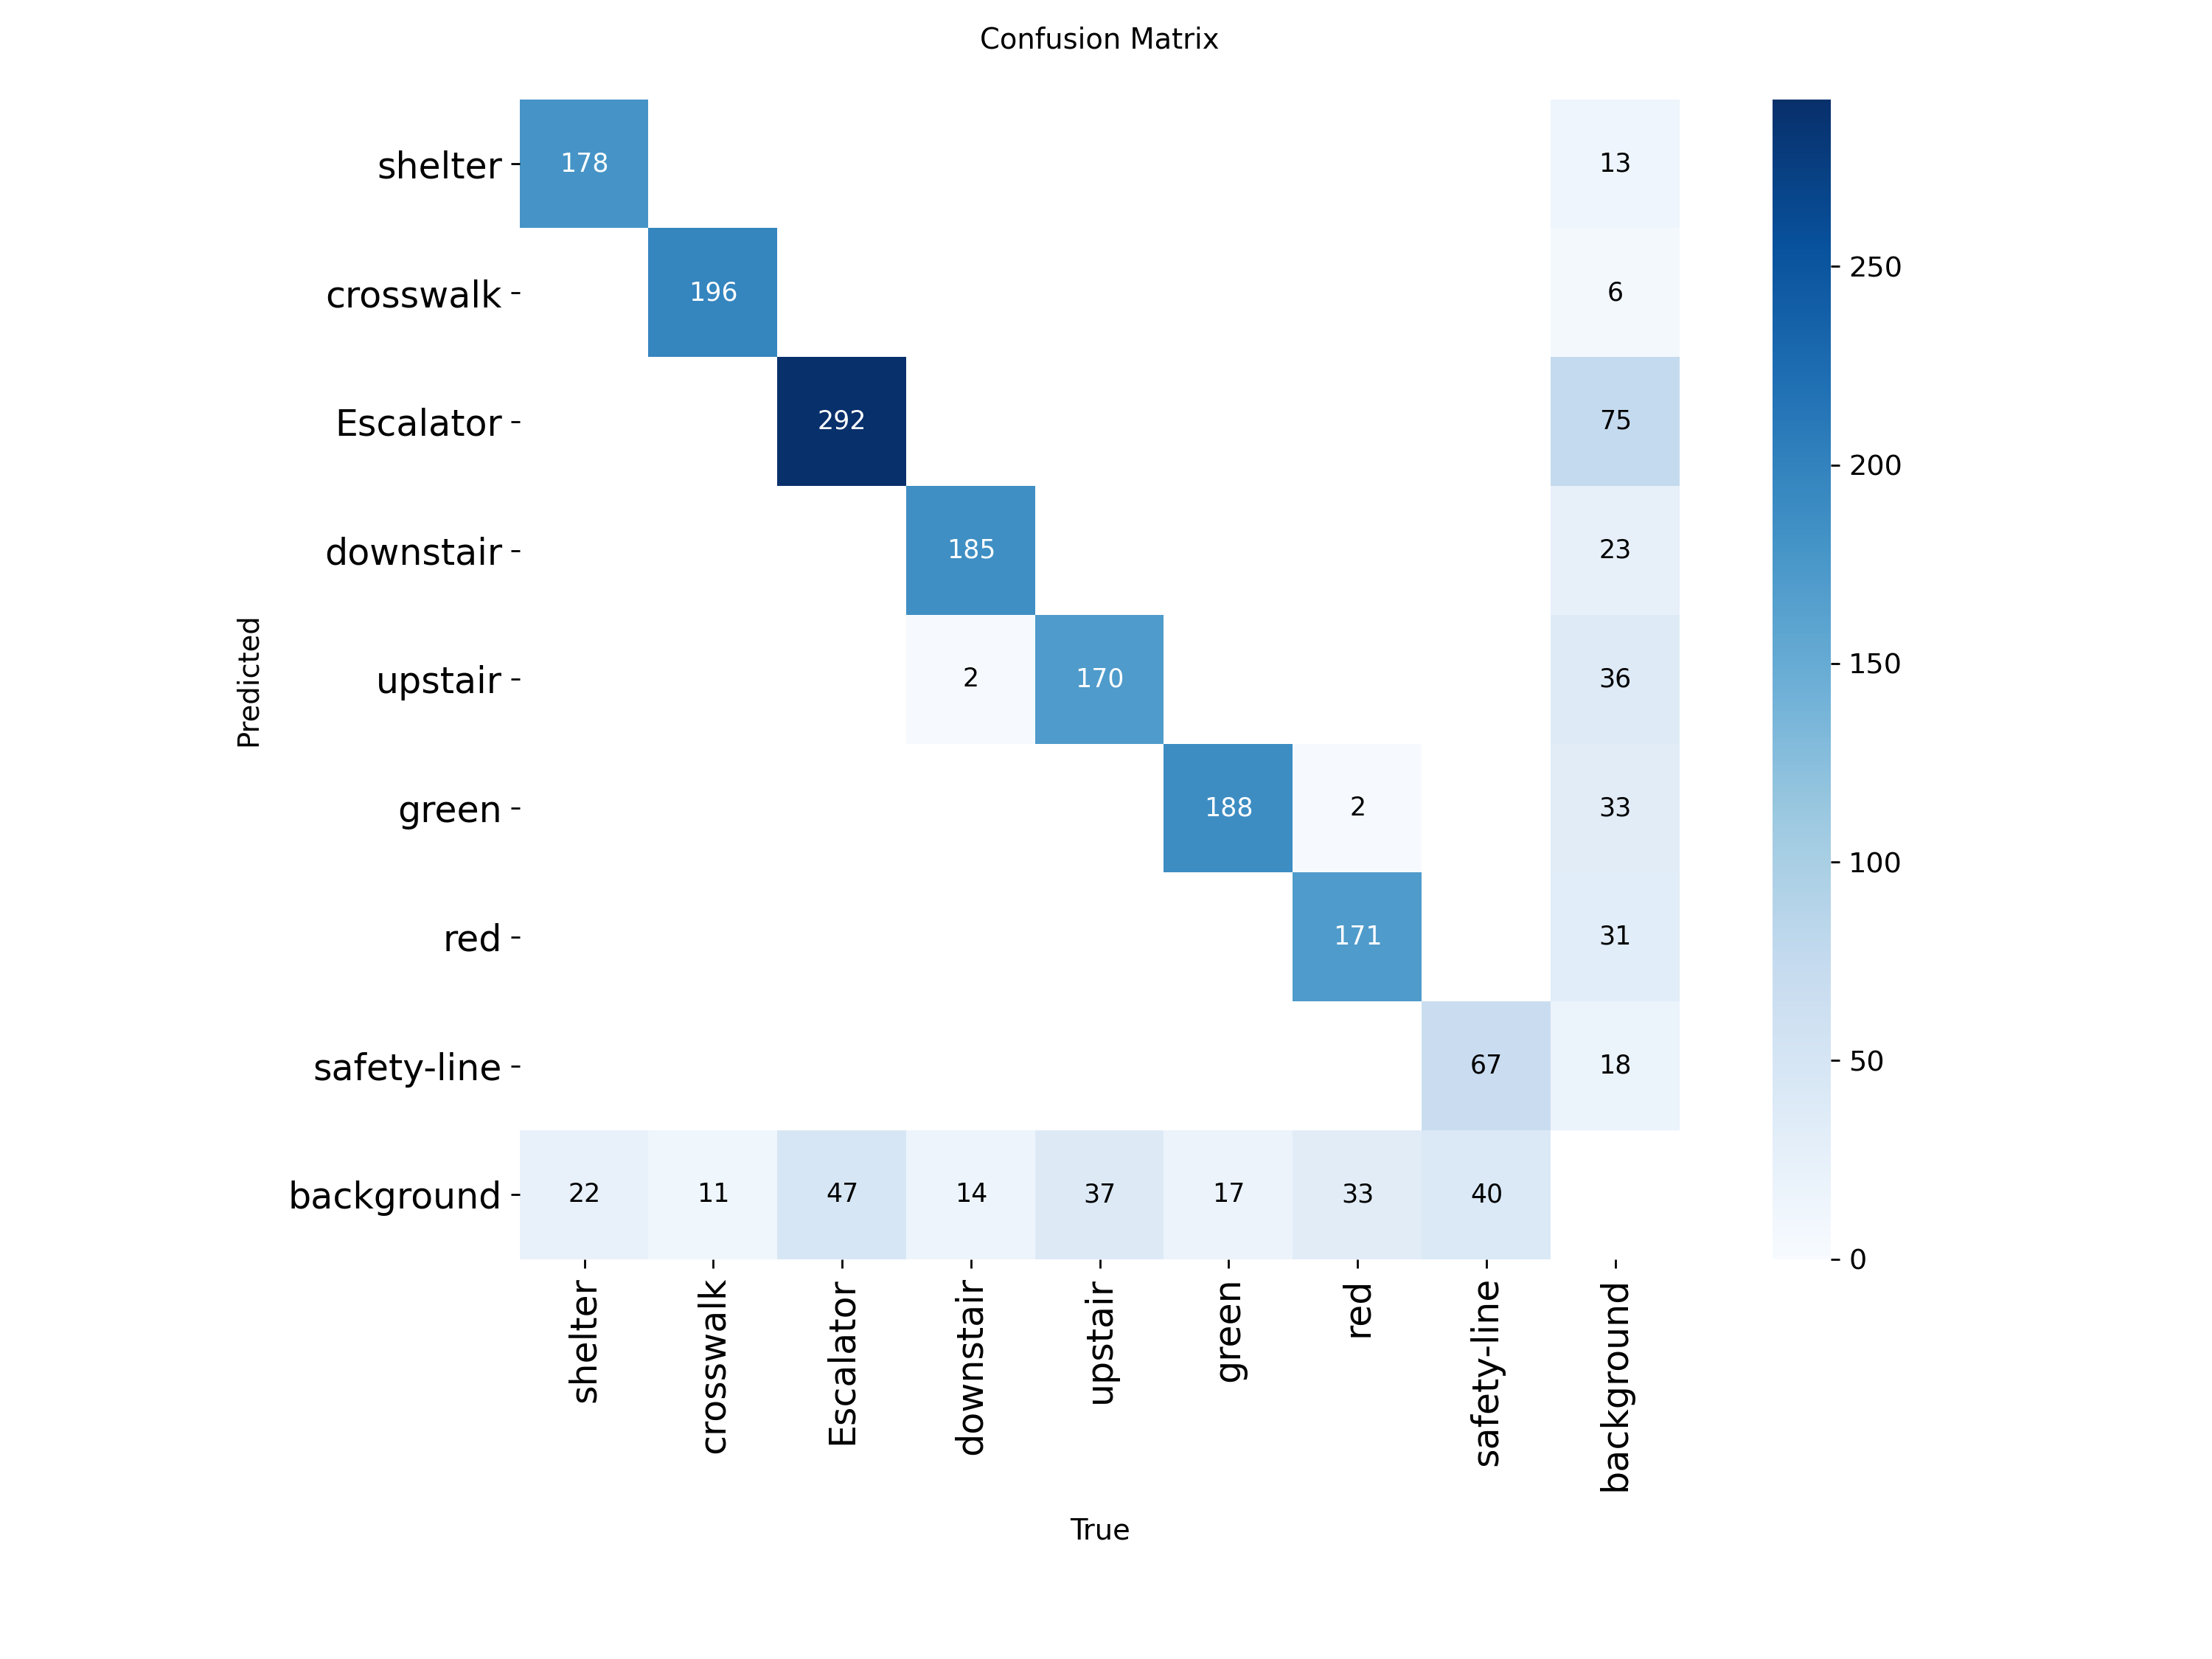

⚠️ Warning: PR_curve.png not found in runs/detect/val3

0: 640x640 3 Escalators, 314.6ms
Speed: 7.7ms preprocess, 314.6ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


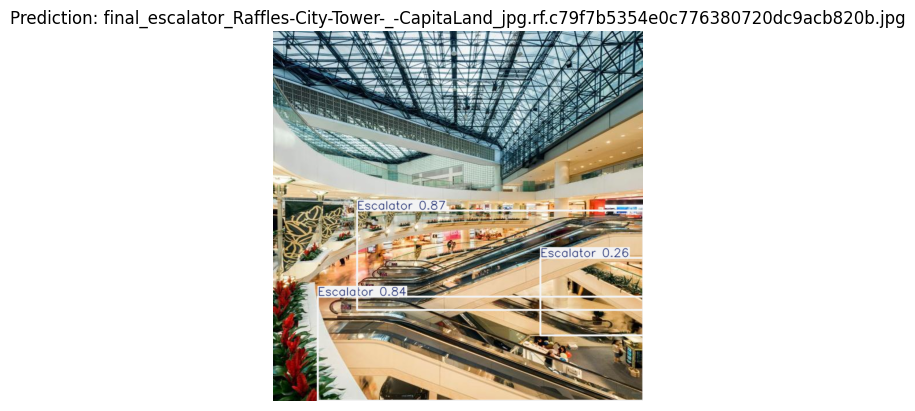


0: 640x640 1 Escalator, 334.4ms
Speed: 4.4ms preprocess, 334.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


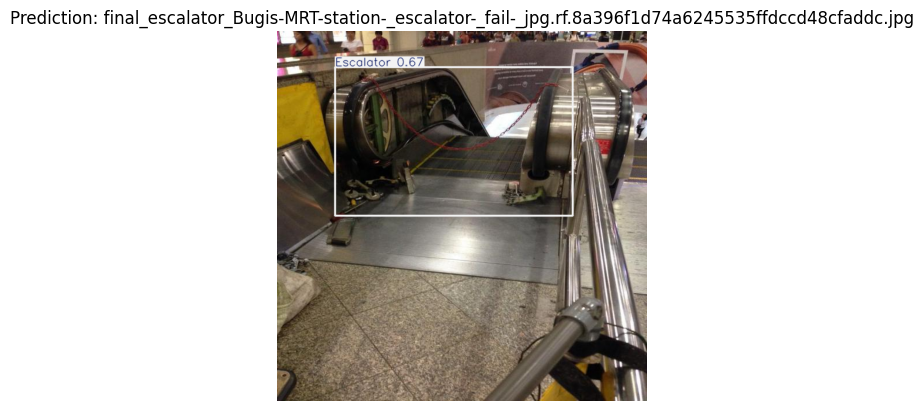


0: 448x640 1 Escalator, 251.0ms
Speed: 4.2ms preprocess, 251.0ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)


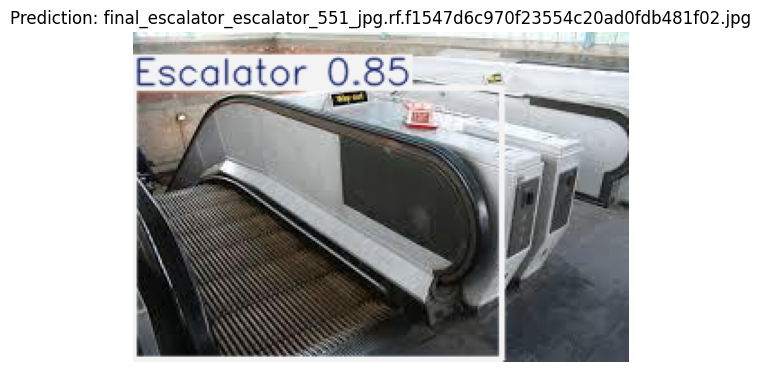


0: 448x640 1 Escalator, 277.0ms
Speed: 4.8ms preprocess, 277.0ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)


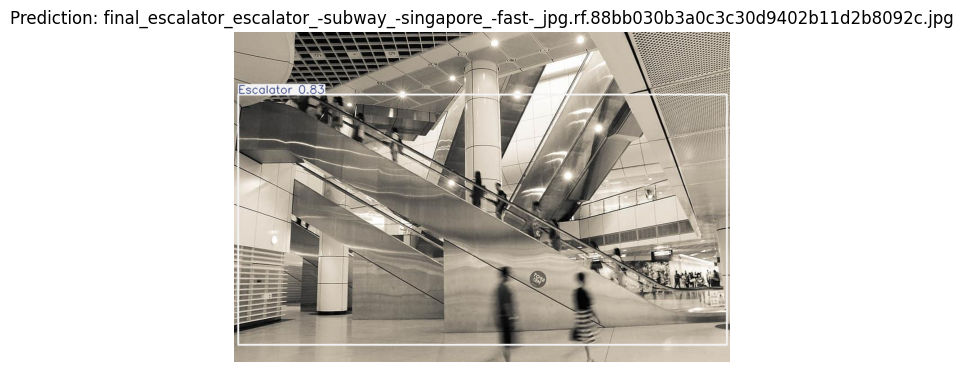


0: 640x640 1 Escalator, 360.9ms
Speed: 8.0ms preprocess, 360.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


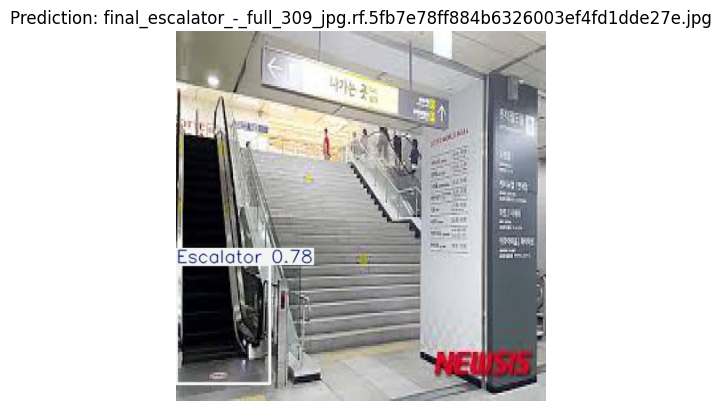

In [9]:
evaluate_yolov8_detector(
    model_path='/content/drive/MyDrive/SmartCane/yolov8n_0.88_58.pt',
    data_yaml='/content/final_dataset/data.yaml'
)


# Text to Speech

In [ ]:
# --- Install requirements for text-to-speech ---
!pip install ultralytics gTTS pydub pyttsx3

In [ ]:

import os
import random
from ultralytics import YOLO
from gtts import gTTS
from pydub import AudioSegment
from pydub.playback import play
from IPython.display import Audio, display

# --- Load trained YOLOv8 model ---
model = YOLO("/content/drive/MyDrive/SmartCane/yolov8n_0.83.pt")

# --- Define class-to-message mapping ---
class_messages = {
    "shelter": "There is a shelter ahead.",
    "crosswalk": "You are approaching a crosswalk.",
    "Escalator": "Escalator detected ahead. Be careful.",
    "downstair": "Downstairs ahead. Watch your step.",
    "upstair": "Upstairs ahead. Watch your step.",
    "green": "Traffic light is green. You may cross.",
    "red": "Traffic light is red. Please stop.",
    "safety-line": "You are near the safety line. Stand behind it."
}

# --- Path to test images ---
test_images_path = "/content/final_dataset/test/images"

# Pick a random image
image_files = [f for f in os.listdir(test_images_path) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
sample_image = os.path.join(test_images_path, random.choice(image_files))
print(f"🖼 Selected image: {sample_image}")

# --- Run YOLOv8 inference ---
results = model(sample_image)

# --- Extract detected class names ---
detected_classes = set()
for r in results:
    for c in r.boxes.cls.cpu().numpy().astype(int):
        detected_classes.add(model.names[c])

print(f"📦 Detected objects: {detected_classes}")

# --- Create and play speech messages ---
for obj in detected_classes:
    if obj in class_messages:
        message = class_messages[obj]
        print(f"🔊 Speaking: {message}")

        # Convert to speech
        tts = gTTS(text=message, lang="en")
        tts.save("message.mp3")

        # Adjust volume to low (e.g., -15 dB)
        sound = AudioSegment.from_mp3("message.mp3") - 15
        sound.export("message_low.mp3", format="mp3")

        # Play audio in Colab
        display(Audio("message_low.mp3", autoplay=True))


🖼 Selected image: /content/final_dataset/test/images/final_escalator_down89_output_output_jpg.rf.78315404cc4f0ced9f6227f85c587400.jpg

image 1/1 /content/final_dataset/test/images/final_escalator_down89_output_output_jpg.rf.78315404cc4f0ced9f6227f85c587400.jpg: 640x640 1 downstair, 672.2ms
Speed: 9.6ms preprocess, 672.2ms inference, 26.7ms postprocess per image at shape (1, 3, 640, 640)
📦 Detected objects: {'downstair'}
🔊 Speaking: Downstairs ahead. Watch your step.


In [ ]:
import json

with open("config.json", "r", encoding="utf-8") as f:
    config = json.load(f)

# Add the missing attribute expected by the model:
config["is_multi_lingual"] = False

# Save it back
with open("config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=4)



In [ ]:
model_url = "https://huggingface.co/Kamtera/persian-tts-male1-vits/resolve/main/checkpoint_88000.pth"
response = requests.get(model_url)
response.raise_for_status()

with open("checkpoint_88000.pth", "wb") as f:
    f.write(response.content)


In [ ]:
!pip install TTS --upgrade


In [ ]:
from TTS.api import TTS

# Load by huggingface repo id - this automatically fetches config and model
tts = TTS("Kamtera/persian-tts-male1-vits")


ValueError: not enough values to unpack (expected 4, got 2)